
## Step 1: Analyze Rating Categories

### Objective
Analyze the distribution of Netflix content ratings to understand how the catalog is classified for different audiences.

### Approach
Load the cleaned Netflix dataset, inspect the `rating` column, check missing values, and calculate the number of records in each rating category.

In [1]:
import pandas as pd 

df = pd.read_csv("../../data/processed/netflix_cleaned.csv")

df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,90,min
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",1,Season
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",1,Season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",125,min


### Inspect the Rating Column

Check the data type, missing values, and available rating categories before performing the analysis.

In [7]:
print("Rating data type:", df["rating"].dtype)
print("Missing rating values:", df["rating"].isna().sum())

print("\nRating categories:")
print(df["rating"].value_counts())

Rating data type: str
Missing rating values: 0

Rating categories:
rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


### Rating Distribution

Visualize the frequency of each rating category to identify the most common ratings in the Netflix dataset.

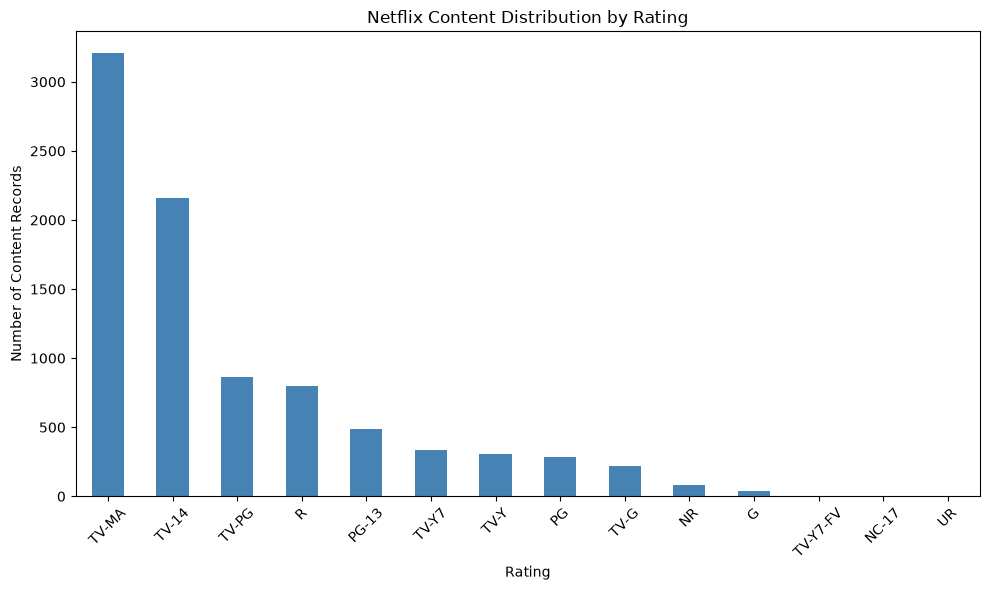

In [21]:
import matplotlib.pyplot as plt

rating_counts = df["rating"].value_counts()

plt.figure(figsize=(10,6))
rating_counts.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Netflix Content Distribution by Rating")
plt.xlabel("Rating")
plt.ylabel("Number of Content Records")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "rating_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Step 2: Identify the Most Common Genres

Analyze the `listed_in` column to identify the most frequent genres and categories in the Netflix catalog.

In [24]:
print("Missing genre values:", df["listed_in"].isna().sum())

print("\nFirst 10 genre entries:")
print(df["listed_in"].head(10))

Missing genre values: 0

First 10 genre entries:
0                                        Documentaries
1    Crime TV Shows, International TV Shows, TV Act...
2                   TV Dramas, TV Horror, TV Mysteries
3                   Children & Family Movies, Comedies
4     Dramas, Independent Movies, International Movies
5                         British TV Shows, Reality TV
6                                     Comedies, Dramas
7    Children & Family Movies, Comedies, Music & Mu...
8                         Dramas, International Movies
9           Children & Family Movies, Music & Musicals
Name: listed_in, dtype: str


### Clean and Count Individual Genres

Some records contain multiple genres separated by commas. Split these values into individual categories so each genre can be counted separately.

In [33]:
# Split genres into separate values
genre_split = df["listed_in"].dropna().str.split(",")

# Put each genre into its own row
genre_list = genre_split.explode().str.strip()

# Count each genre
genre_counts = genre_list.value_counts()

print(genre_counts.head(10))

listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


### Visualize the Most Common Genres

Create a horizontal bar chart to compare the frequency of the ten most common Netflix genres and categories.

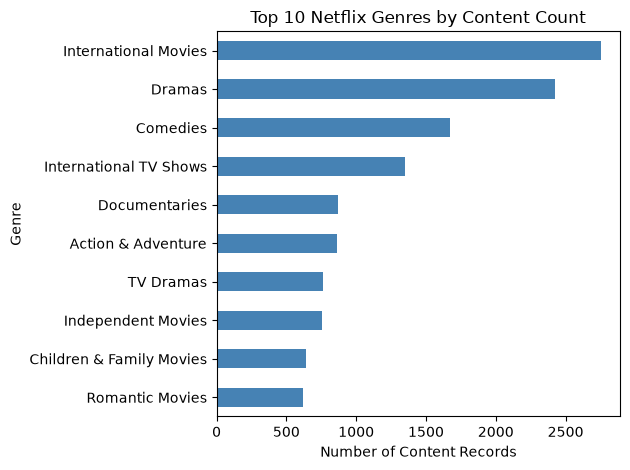

In [42]:
import matplotlib.pyplot as plt

top_10_genres = genre_counts.head(10)

plt.Figure(figsize=(10,6))

top_10_genres.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Top 10 Netflix Genres by Content Count")
plt.xlabel("Number of Content Records")
plt.ylabel("Genre")
plt.tight_layout()

plt.savefig(
    "top_10_genres.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Step 3: Compare Ratings Across Content Types

Compare rating distributions for Movies and TV Shows to understand how content classifications differ between the two content types.

In [43]:
# Count ratings separately for Movies and TV Shows
rating_by_type = pd.crosstab(df["rating"], df["type"])

print(rating_by_type)

type      Movie  TV Show
rating                  
G            41        0
NC-17         3        0
NR           75        4
PG          287        0
PG-13       490        0
R           797        2
TV-14      1427      730
TV-G        126       94
TV-MA      2062     1143
TV-PG       540      321
TV-Y        131      175
TV-Y7       139      194
TV-Y7-FV      5        1
UR            3        0


## Step 4: Create Interactive Visualizations

Visualize rating distributions across Movies and TV Shows to compare their content classifications.

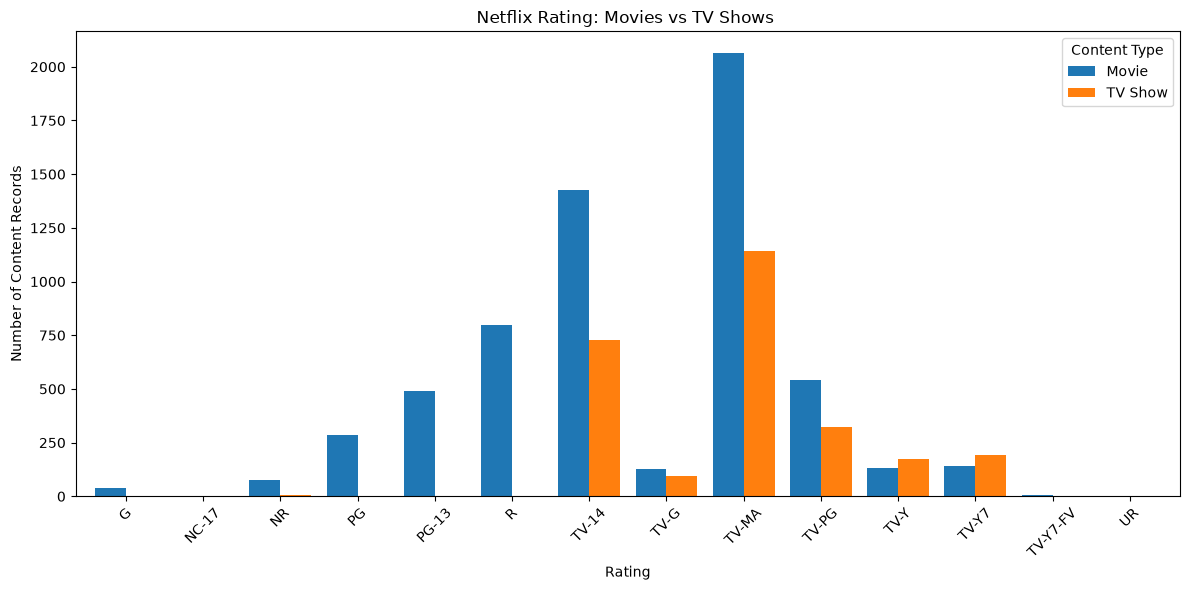

In [54]:
import matplotlib.pyplot as plt

rating_by_type.plot(
    kind="bar",
    figsize=(12,6),
    width=0.8
)

plt.title("Netflix Rating: Movies vs TV Shows ")
plt.xlabel("Rating")
plt.ylabel("Number of Content Records")
plt.xticks(rotation=45)
plt.legend(title="Content Type")
plt.tight_layout()

plt.savefig("rating_by_content_type.png", dpi=300, bbox_inches="tight")
plt.show()

### Interactive Rating Comparison

Create an interactive chart that allows users to hover over the bars to inspect the number of records for each rating and content type.

In [55]:
%pip install plotly

  Using cached plotly-7.1.0-py3-none-any.whl.metadata (8.8 kB)
Using cached plotly-7.1.0-py3-none-any.whl (9.7 MB)

   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]

In [57]:
import plotly.express as px

rating_long = rating_by_type.reset_index().melt(
    id_vars="rating",
    var_name="Content Type",
    value_name="Content Count"
)

fig = px.bar(
    rating_long,
    x="rating",
    y="Content Count",
    color="Content Type",
    barmode="group",
    title="Interactive Netflix Ratings: Movies vs TV Shows",
    hover_data=["Content Count"]
)

fig.show()

In [58]:
# Save the interactive chart as an HTML file
fig.write_html("interactive_ratings_by_content_type.html")

print("Interactive chart saved successfully!")

Interactive chart saved successfully!


## Step 5: Present Audience Insights

### Key Findings

1. **Most common rating:** TV-MA is the most frequent rating in the dataset, with 3,205 records.
2. **Second most common rating:** TV-14 has 2,157 records.
3. **Genre distribution:** International Movies is the most common genre/category, followed by Dramas and Comedies.
4. **Movie rating patterns:** TV-MA and TV-14 are the most frequent ratings among Movies.
5. **TV Show rating patterns:** TV-MA and TV-14 are also the most frequent ratings among TV Shows.

### Business Interpretation

The dataset contains a substantial number of records classified as TV-MA and TV-14. International Movies, Dramas, and Comedies are the most frequently listed categories. These patterns describe the catalog's classification and category distribution; they do not directly measure audience preferences or viewing figures.

### Data Limitation

A title may belong to multiple genres. Rating and genre counts should therefore be interpreted as category frequencies rather than mutually exclusive audience segments.